# Análise Exploratória de Dados da Camada Gold

Este notebook explora as Feature Stores e os indicadores Parquet consolidados em `data/features/`.

### Objetivos
1. Analisar municípios frente à meta oficial de 80% em 2030, usando a rede Municipal (`"3"`).
2. Comparar as UFs na rede Pública (`"5"`) e identificar diferenças territoriais.
3. Acompanhar a evolução nacional, distinguindo resultados oficiais de dados sintéticos de teste.
4. Examinar a distribuição municipal e as relações entre variáveis.

As Feature Stores municipal, estadual e nacional são arquivos separados. A visão Pública de UF e Brasil resulta da agregação ponderada das redes Estadual (`"2"`) e Municipal (`"3"`); ela não é uma média simples das taxas dessas redes. No snapshot atual, 2023 e 2024 são os anos oficiais; 2025 e 2026 contêm eventos sintéticos e ficam fora das comparações oficiais.


In [8]:
# 1. Configuração do Ambiente e Importação de Bibliotecas
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações estéticas do Seaborn / Matplotlib
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.unicode_minus"] = False

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 1. Carregando Dados da Camada Gold (`data/features/`)

Este notebook lê os arquivos Parquet gerados pelo pipeline (`data/features/`). Para evitar que os eventos sintéticos de teste distorçam as análises, os gráficos comparativos usam apenas os anos oficiais de 2023 e 2024. Os dados de teste de 2025 e 2026 são identificados separadamente na cobertura e na evolução nacional.

In [9]:
# Carrega as Feature Stores municipal, estadual e nacional
BASE_FEATURES = os.path.join("..", "data", "features")
FEATURE_FILES = {
    "municipio": "gold_features_alfabetizacao.parquet",
    "uf": "gold_features_alfabetizacao_uf.parquet",
    "brasil": "gold_features_alfabetizacao_brasil.parquet",
}

if not os.path.exists(os.path.join(BASE_FEATURES, FEATURE_FILES["municipio"])):
    BASE_FEATURES = os.path.join("data", "features")

feature_paths = {
    level: os.path.join(BASE_FEATURES, filename)
    for level, filename in FEATURE_FILES.items()
}
for dataset_path in feature_paths.values():
    if not os.path.exists(dataset_path):
        raise FileNotFoundError(
            f"Arquivo não encontrado: {dataset_path}. Execute a pipeline batch/eventos para gerar a Gold."
        )

df_features_municipal = pd.read_parquet(feature_paths["municipio"])
df_features_uf = pd.read_parquet(feature_paths["uf"])
df_features_brasil = pd.read_parquet(feature_paths["brasil"])
required_columns = {
    "ano", "rede", "serie", "taxa_alfabetizacao_recalculada",
    "meta_pactuada_2030", "gap_para_meta", "rotulo_alvo",
}
for level, dataframe in {
    "municipio": df_features_municipal,
    "uf": df_features_uf,
    "brasil": df_features_brasil,
}.items():
    missing_columns = required_columns.difference(dataframe.columns)
    if missing_columns:
        raise ValueError(f"Feature Store de {level} sem colunas: {sorted(missing_columns)}")
    if dataframe.empty:
        raise ValueError(f"Feature Store de {level} está vazia: {feature_paths[level]}")

ANALYSIS_SERIES = "2"
OFFICIAL_DATA_YEARS = {2023, 2024}
df_features_municipal = df_features_municipal[
    (df_features_municipal["rede"].astype(str) == "3")
    & (df_features_municipal["serie"].astype(str) == ANALYSIS_SERIES)
].copy()
df_features_uf = df_features_uf[
    (df_features_uf["rede"].astype(str) == "5")
    & (df_features_uf["serie"].astype(str) == ANALYSIS_SERIES)
].copy()
df_features_brasil = df_features_brasil[
    (df_features_brasil["rede"].astype(str) == "5")
    & (df_features_brasil["serie"].astype(str) == ANALYSIS_SERIES)
].copy()
for level, dataframe in {
    "municipal": df_features_municipal,
    "UF": df_features_uf,
    "Brasil": df_features_brasil,
}.items():
    if dataframe.empty:
        raise ValueError(f"Não há registros da 2ª série para a rede esperada no nível {level}.")

available_official_years = OFFICIAL_DATA_YEARS.intersection(
    df_features_municipal["ano"].astype(int).unique()
)
if not available_official_years:
    raise ValueError(
        f"Nenhum ano oficial conhecido {sorted(OFFICIAL_DATA_YEARS)} está disponível."
    )
latest_year = max(available_official_years)
df_features_municipal_latest = df_features_municipal[
    df_features_municipal["ano"] == latest_year
].copy()
df_features_uf_latest = df_features_uf[df_features_uf["ano"] == latest_year].copy()
if df_features_uf_latest.empty:
    raise ValueError(f"Não há dados de UF no ano oficial {latest_year}.")

coverage_rows = []
coverage_frames = [
    ("Municípios (rede Municipal)", df_features_municipal, "id_municipio"),
    ("UFs (rede Pública)", df_features_uf, "sigla_uf"),
    ("Brasil (rede Pública)", df_features_brasil, None),
]
for level_name, dataframe, entity_column in coverage_frames:
    for year, year_data in dataframe.groupby("ano"):
        coverage_rows.append({
            "Nível": level_name,
            "Ano": int(year),
            "Registros": len(year_data),
            "Unidades": year_data[entity_column].nunique() if entity_column else len(year_data),
            "Classificação": "Oficial" if int(year) in OFFICIAL_DATA_YEARS else "Sintético (teste)",
        })
coverage_summary = pd.DataFrame(coverage_rows).sort_values(["Nível", "Ano"])
print(
    f"Ano de referência oficial: {latest_year}. "
    "Os anos classificados como sintéticos não entram nos rankings nem nos indicadores oficiais."
)
coverage_summary


Ano de referência oficial: 2024. Os anos classificados como sintéticos não entram nos rankings nem nos indicadores oficiais.


,Nível,Ano,Registros,Unidades,Classificação
8,Brasil (rede Pública),2023,1,1,Oficial
9,Brasil (rede Pública),2024,1,1,Oficial
10,Brasil (rede Pública),2025,1,1,Sintético (teste)
11,Brasil (rede Pública),2026,1,1,Sintético (teste)
0,Municípios (rede Municipal),2023,4822,4822,Oficial
1,Municípios (rede Municipal),2024,5451,5451,Oficial
2,Municípios (rede Municipal),2025,14,14,Sintético (teste)
3,Municípios (rede Municipal),2026,8,8,Sintético (teste)
4,UFs (rede Pública),2023,23,23,Oficial
5,UFs (rede Pública),2024,27,27,Oficial


## 2. Visão Executiva: Status da Meta Oficial (2030)

Percentual de municípios que atingiram 80% no último ano oficial disponível, usando a rede Municipal (`"3"`) e a 2ª série. Os eventos sintéticos de teste ficam fora deste indicador.


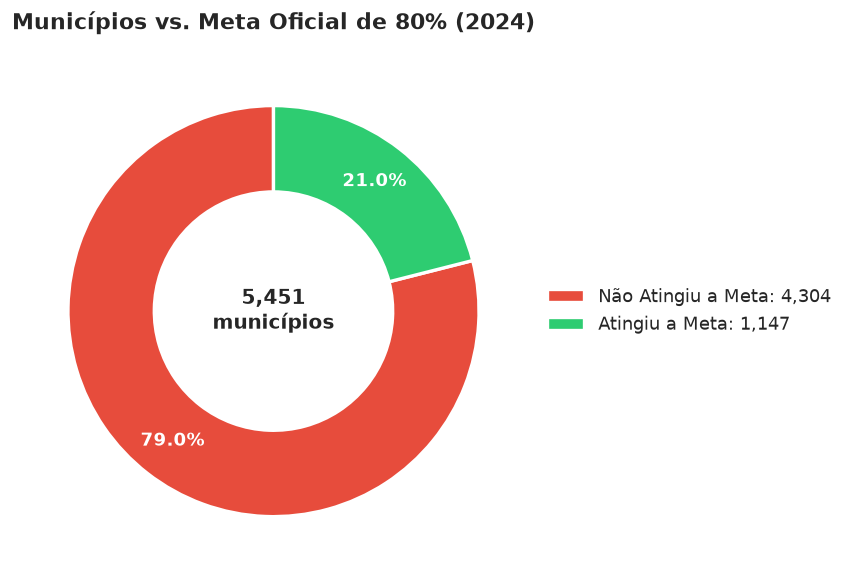

In [10]:
# Municípios no último ano oficial, comparados à meta oficial de 80%
status_counts = df_features_municipal_latest["rotulo_alvo"].value_counts()
status_colors = {
    "Atingiu a Meta": "#2ecc71",
    "Não Atingiu a Meta": "#e74c3c",
    "Sem Resultado Calculado": "#95a5a6",
}

fig, ax = plt.subplots(figsize=(8, 5))
wedges, _, autotexts = ax.pie(
    status_counts,
    autopct="%1.1f%%",
    startangle=90,
    colors=[status_colors[label] for label in status_counts.index],
    pctdistance=0.80,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),
)

plt.setp(autotexts, size=11, weight="bold", color="white")
ax.text(
    0, 0, f"{len(df_features_municipal_latest):,}\nmunicípios",
    ha="center", va="center", fontsize=12, weight="bold",
)
ax.legend(
    wedges,
    [f"{label}: {count:,}" for label, count in status_counts.items()],
    loc="center left", bbox_to_anchor=(1, 0.5), frameon=False,
)
ax.set_title(
    f"Municípios vs. Meta Oficial de 80% ({latest_year})",
    fontsize=13,
    pad=15,
    weight="bold",
)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## 3. Análise Territorial: Taxa Ponderada por UF

Ranking da taxa na rede Pública (`"5"`) no último ano oficial disponível, derivada da agregação ponderada das redes Estadual e Municipal. As amostras sintéticas de teste não são representativas das UFs.


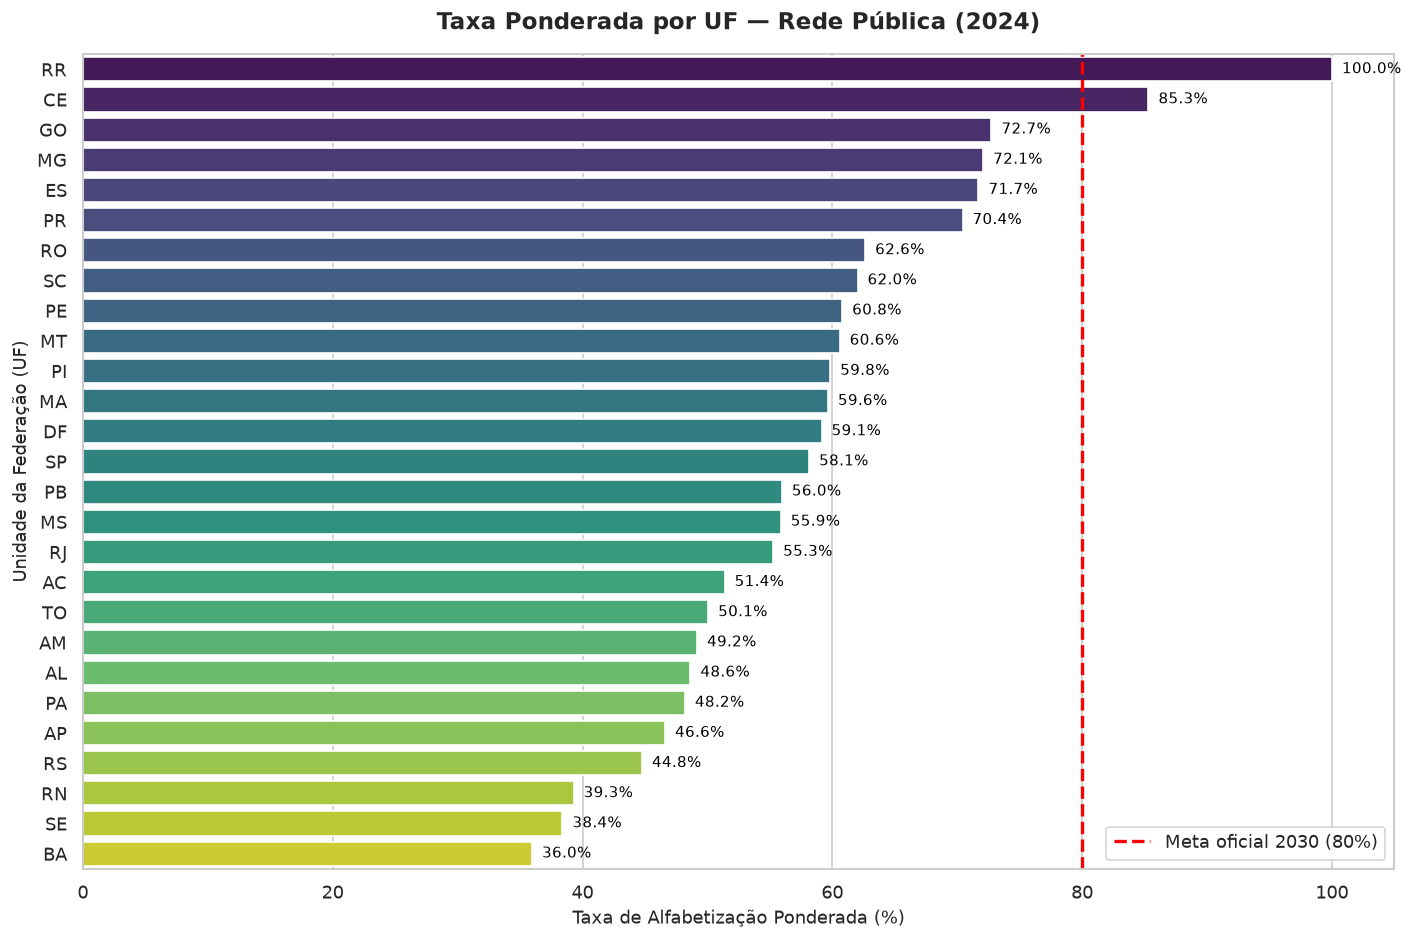

In [11]:
# Ranking das UFs na rede Pública no último ano oficial disponível
latest_uf_year = latest_year
uf_summary = df_features_uf_latest.copy()
uf_summary = uf_summary.sort_values("taxa_alfabetizacao_recalculada", ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))
barplot = sns.barplot(
    data=uf_summary,
    x="taxa_alfabetizacao_recalculada",
    y="sigla_uf",
    hue="sigla_uf",
    palette="viridis",
    legend=False,
    ax=ax,
)

ax.axvline(
    x=80.0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Meta oficial 2030 (80%)",
)
for patch in barplot.patches:
    width = patch.get_width()
    if width > 0:
        barplot.annotate(
            f"{width:.1f}%",
            (width + 0.8, patch.get_y() + patch.get_height() / 2.0),
            ha="left",
            va="center",
            fontsize=9,
            color="black",
        )

ax.set_title(f"Taxa Ponderada por UF — Rede Pública ({latest_uf_year})", fontsize=14, pad=15, weight="bold")
ax.set_xlabel("Taxa de Alfabetização Ponderada (%)", fontsize=11)
ax.set_ylabel("Unidade da Federação (UF)", fontsize=11)
ax.set_xlim(0, 105)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


## 4. Evolução Nacional: Rede Pública

Os anos oficiais são exibidos como uma série contínua. Eventos sintéticos de teste aparecem como pontos separados e não são conectados à série oficial.


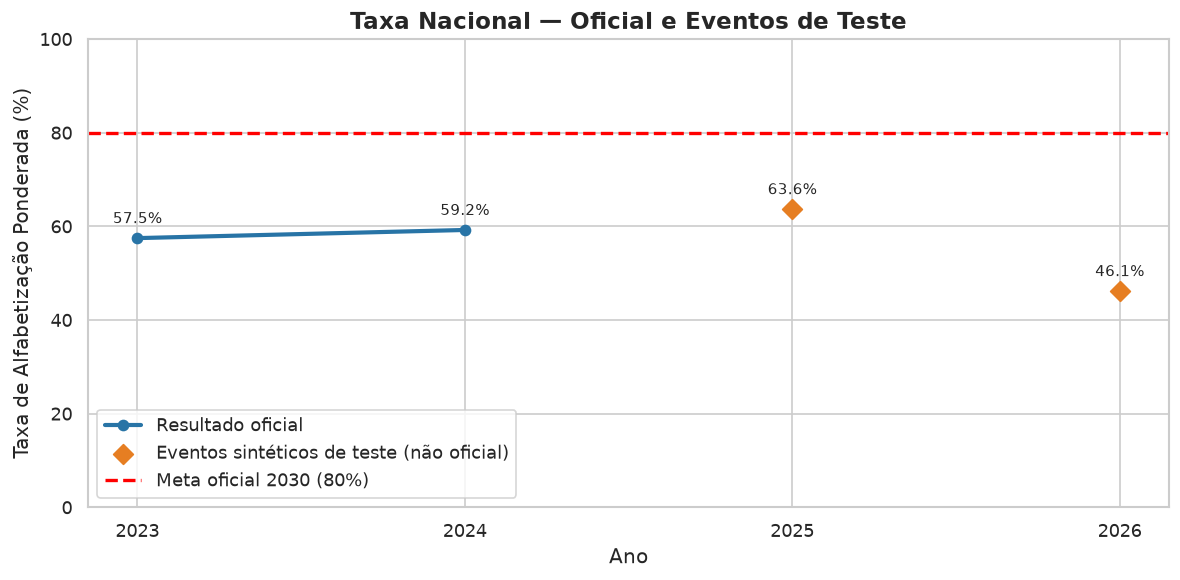

In [12]:
brasil_official = df_features_brasil[
    df_features_brasil["ano"].isin(OFFICIAL_DATA_YEARS)
].sort_values("ano")
brasil_synthetic = df_features_brasil[
    ~df_features_brasil["ano"].isin(OFFICIAL_DATA_YEARS)
].sort_values("ano")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    brasil_official["ano"],
    brasil_official["taxa_alfabetizacao_recalculada"],
    marker="o",
    linewidth=2.5,
    color="#2874a6",
    label="Resultado oficial",
)
if not brasil_synthetic.empty:
    ax.scatter(
        brasil_synthetic["ano"],
        brasil_synthetic["taxa_alfabetizacao_recalculada"],
        marker="D", s=70, color="#e67e22",
        label="Eventos sintéticos de teste (não oficial)", zorder=3,
    )
ax.axhline(80.0, color="red", linestyle="--", linewidth=2, label="Meta oficial 2030 (80%)")
brasil_display = pd.concat([brasil_official, brasil_synthetic]).sort_values("ano")
for row in brasil_display.itertuples():
    ax.annotate(
        f"{row.taxa_alfabetizacao_recalculada:.1f}%",
        (row.ano, row.taxa_alfabetizacao_recalculada),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
ax.set_title("Taxa Nacional — Oficial e Eventos de Teste", fontsize=14, weight="bold")
ax.set_xlabel("Ano")
ax.set_ylabel("Taxa de Alfabetização Ponderada (%)")
ax.set_ylim(0, 100)
ax.set_xticks(brasil_display["ano"].astype(int))
ax.legend()
plt.tight_layout()
plt.show()


## 5. Análise de Variabilidade: Municípios

Distribuição das taxas recalculadas por município no último ano oficial disponível, para a rede Municipal (`"3"`), em relação à meta oficial de 80%.


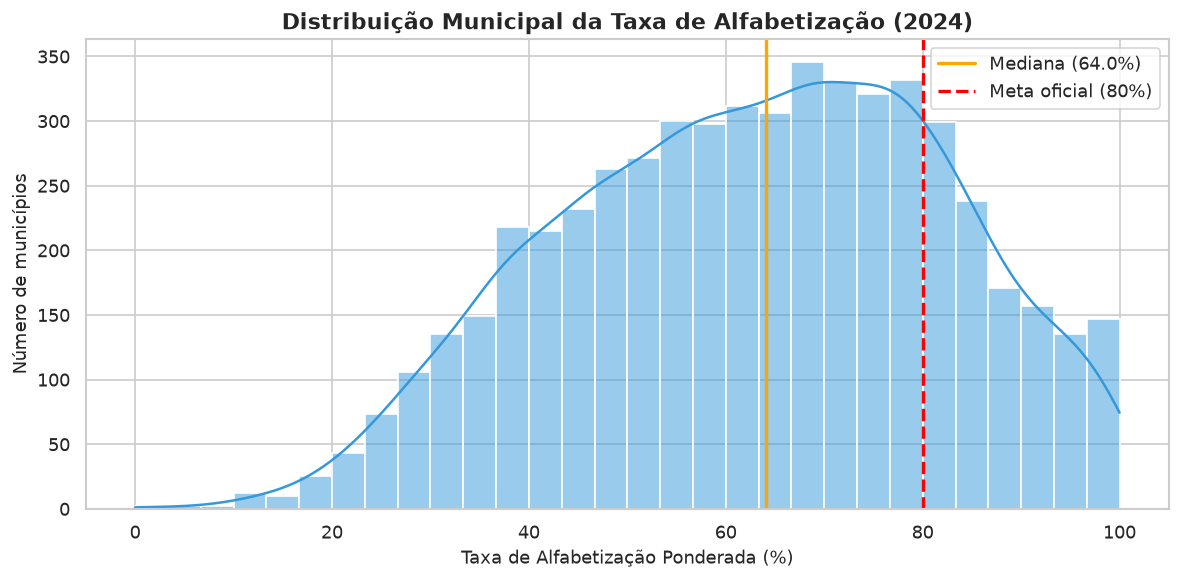

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(
    df_features_municipal_latest["taxa_alfabetizacao_recalculada"],
    kde=True,
    color="#3498db",
    bins=30,
)
median_rate = df_features_municipal_latest["taxa_alfabetizacao_recalculada"].median()
plt.axvline(
    median_rate,
    color="orange",
    linestyle="-",
    linewidth=2,
    label=f"Mediana ({median_rate:.1f}%)",
)
plt.axvline(80.0, color="red", linestyle="--", linewidth=2, label="Meta oficial (80%)")

plt.title(f"Distribuição Municipal da Taxa de Alfabetização ({latest_year})", fontsize=13, weight="bold")
plt.xlabel("Taxa de Alfabetização Ponderada (%)", fontsize=11)
plt.ylabel("Número de municípios", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()


## 6. Matriz de Correlação das Variáveis Preditivas (Feature Store ML)

Avaliação das relações entre o volume de alunos, a proficiência e o indicador recalculado.

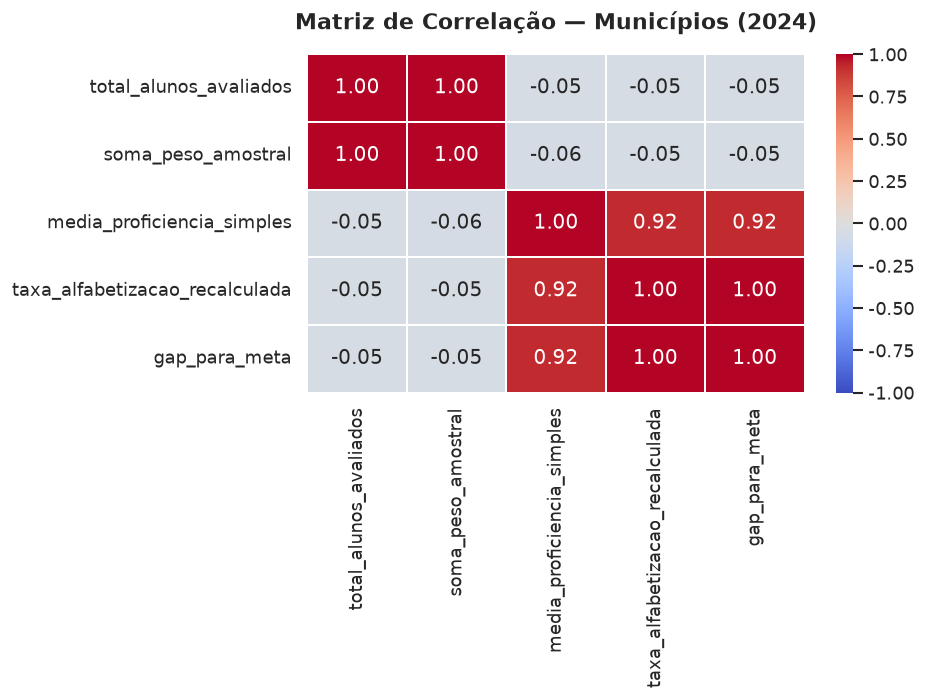

In [14]:
# Correlação das variáveis para municípios no último ano oficial
numeric_cols = [
    "total_alunos_avaliados",
    "soma_peso_amostral",
    "media_proficiencia_simples",
    "taxa_alfabetizacao_recalculada",
    "gap_para_meta",
]

corr_matrix = df_features_municipal_latest[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=1)
plt.title(f"Matriz de Correlação — Municípios ({latest_year})", fontsize=13, pad=15, weight="bold")
plt.tight_layout()
plt.show()


## 7. Observações

1. Avalie risco de vazamento de alvo ao usar `taxa_alfabetizacao_recalculada` e `gap_para_meta` como variáveis explicativas.
2. As comparações deste notebook usam exclusivamente a meta oficial de 80% em 2030.
3. A validação cruzada municipal deve ser conferida no manifesto da execução Gold correspondente.
4. Os geradores criam registros sintéticos; eventos de teste não representam resultados oficiais do Inep.
